# Unit 3 – Covariance and Pearson Correlation
**Module:** Machine Learning (ML_PCOM7E)  |  **e-Portfolio activity:** Correlation and Regression (1 of 4)

**Aim:** compute covariance and Pearson's r from first principles, check them against NumPy/SciPy, and observe how changing the data (noise, outliers, non-linearity) changes the result.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
rng_seed = 42   # change me

N, NOISE = 100, 8.0           # <- change sample size and noise to experiment
rng = np.random.default_rng(rng_seed)
height = rng.normal(170, 10, N)                          # cm
weight = 0.9*(height-170) + 70 + rng.normal(0, NOISE, N)  # kg, linearly related plus noise
def cov(x,y): return np.sum((x-x.mean())*(y-y.mean()))/(len(x)-1)
def pearson(x,y): return cov(x,y)/(x.std(ddof=1)*y.std(ddof=1))
print(f"Covariance (manual) : {cov(height,weight):8.3f}   NumPy: {np.cov(height,weight)[0,1]:8.3f}")
r_scipy, p = stats.pearsonr(height,weight)
print(f"Pearson r (manual)  : {pearson(height,weight):8.3f}   SciPy: {r_scipy:8.3f}  (p = {p:.2e})")

Covariance (manual) :   60.042   NumPy:   60.042
Pearson r (manual)  :    0.704   SciPy:    0.704  (p = 3.13e-16)


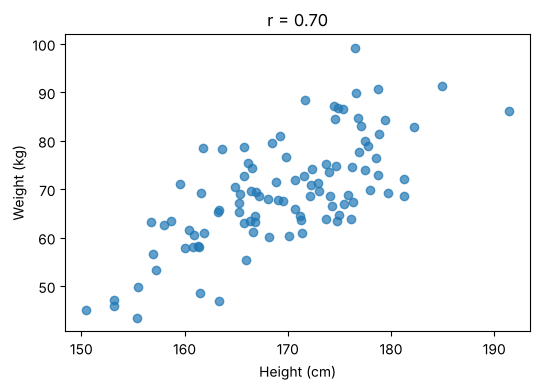

In [2]:
fig,ax=plt.subplots(figsize=(5.5,4)); ax.scatter(height,weight,alpha=.7); ax.set(xlabel="Height (cm)",ylabel="Weight (kg)",title=f"r = {pearson(height,weight):.2f}")
plt.tight_layout(); plt.savefig("fig_corr_scatter.png",dpi=130); plt.show()

## Experiment A – how noise weakens correlation

In [3]:
rows=[]
for noise in [1,4,8,16,32]:
    r=np.random.default_rng(1); h=r.normal(170,10,N); w=0.9*(h-170)+70+r.normal(0,noise,N)
    rows.append((noise,cov(h,w),pearson(h,w)))
tab=pd.DataFrame(rows,columns=["noise_sd","covariance","pearson_r"]).round(3); tab

,noise_sd,covariance,pearson_r
0,1,65.692,0.992
1,4,65.002,0.885
2,8,64.082,0.685
3,16,62.241,0.415
4,32,58.559,0.210


## Experiment B – one outlier, and a non-linear relationship that Pearson misses

r without outlier 0.704 -> with one outlier 0.458
U-shaped data: Pearson r = 0.005, Spearman rho = -0.002  (strong dependence, near-zero r)


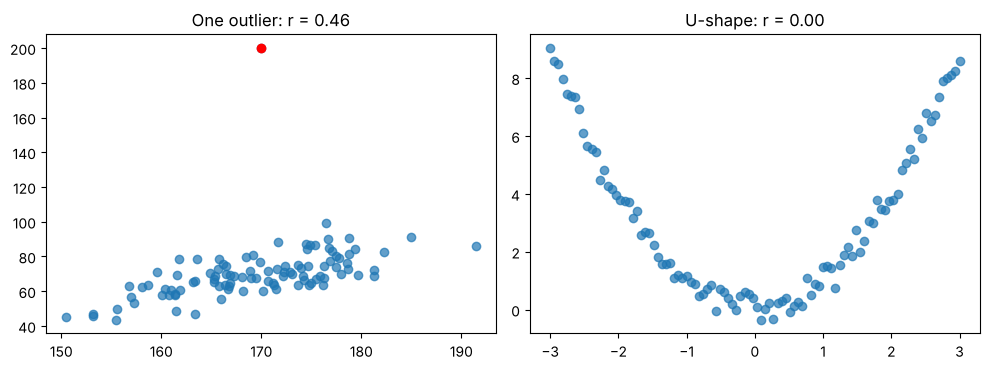

In [4]:
h2=np.append(height,170); w2=np.append(weight,200)           # add one extreme point
print(f"r without outlier {pearson(height,weight):.3f} -> with one outlier {pearson(h2,w2):.3f}")
x=np.linspace(-3,3,100); y=x**2+np.random.default_rng(0).normal(0,.3,100)   # perfect U shape
rho,_=stats.spearmanr(x,y)
print(f"U-shaped data: Pearson r = {pearson(x,y):.3f}, Spearman rho = {rho:.3f}  (strong dependence, near-zero r)")
fig,ax=plt.subplots(1,2,figsize=(10,3.8))
ax[0].scatter(h2,w2,alpha=.7); ax[0].scatter([170],[200],c="red"); ax[0].set_title(f"One outlier: r = {pearson(h2,w2):.2f}")
ax[1].scatter(x,y,alpha=.7); ax[1].set_title(f"U-shape: r = {pearson(x,y):.2f}")
plt.tight_layout(); plt.savefig("fig_corr_experiments.png",dpi=130); plt.show()

## Interpretation
* Covariance has the units of both variables (cm·kg), so its size is hard to compare; Pearson's r divides by both standard deviations and is bounded in [-1, 1].
* As noise grows, r falls steadily while the true underlying slope is unchanged: correlation measures *strength*, not *slope*.
* A single outlier can move r substantially, and a perfect non-linear (U-shaped) dependence can give r close to 0. Always plot the data before trusting r.
* Correlation is not causation: even r close to 1 says nothing about which variable drives the other.